# Physics-Informed Neural Networks in 1D

We first train a regular neural network to learn the cosine from a few points. Then we train a Physics-Informed Neural Network (PINN) using the differential equation and its initial conditions.

The idea is to see what happens where we did not give the networks any cosine values.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)
torch.set_num_threads(1)  # One CPU thread is enough for these small networks.

## 1. Learning the cosine from data

We sample 20 points on $[0, 2\pi]$. We use the first 16 for training and keep the last four for testing. All the test points are to the right of the training interval, so this is a test of extrapolation.

In [2]:
x_data = torch.linspace(0, 2 * math.pi, 20).reshape(-1, 1)
y_data = torch.cos(x_data)

x_train, x_test = x_data[:16], x_data[16:]
y_train, y_test = y_data[:16], y_data[16:]

BATCH_SIZE = 4
N_EPOCHS = 5000
LR = 1e-3

train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True
)
criterion = nn.MSELoss()

Both models use the same network with two hidden layers. We use Tanh because it is smooth and we will need second derivatives for the PINN.

In [3]:
class NeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(1, 30),
            nn.Tanh(),
            nn.Linear(30, 30),
            nn.Tanh(),
            nn.Linear(30, 1),
        )

    def forward(self, x):
        return self.layers(x)


baseline = NeuralNet()
pinn = NeuralNet()
pinn.load_state_dict(baseline.state_dict())
optimizer = torch.optim.Adam(baseline.parameters(), lr=LR)

We start both models with the same weights. For now, we update only the regular network using the training batches. Every 1000 epochs we compute the training and test MSE with the current model.

In [4]:
for epoch in range(1, N_EPOCHS + 1):
    for x_batch, y_batch in train_loader:
        optimizer.zero_grad()
        prediction = baseline(x_batch)
        loss = criterion(prediction, y_batch)
        loss.backward()
        optimizer.step()

    if epoch == 1 or epoch % 1000 == 0:
        with torch.no_grad():
            train_mse = criterion(baseline(x_train), y_train)
            test_mse = criterion(baseline(x_test), y_test)
        print(f'Epoch {epoch:4d} | Train MSE: {train_mse.item():.3e} | Test MSE: {test_mse.item():.3e}')

Epoch    1 | Train MSE: 4.035e-01 | Test MSE: 9.853e-01


Epoch 1000 | Train MSE: 2.492e-05 | Test MSE: 5.076e-02


Epoch 2000 | Train MSE: 7.978e-05 | Test MSE: 4.242e-02


Epoch 3000 | Train MSE: 1.433e-05 | Test MSE: 3.878e-02


Epoch 4000 | Train MSE: 6.580e-03 | Test MSE: 2.396e-02


Epoch 5000 | Train MSE: 6.971e-06 | Test MSE: 3.050e-02


We can see where the prediction starts to move away from the cosine. The shaded part starts at the last training point.

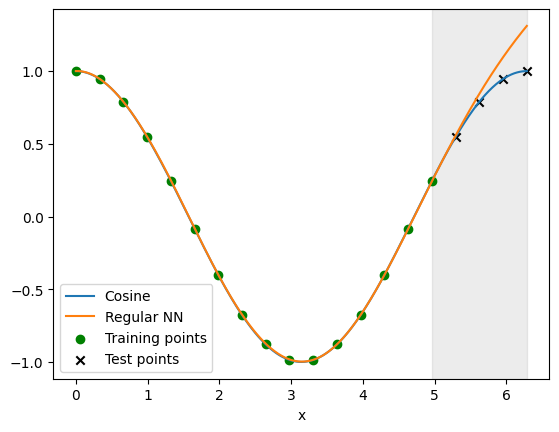

In [5]:
grid = torch.linspace(0, 2 * math.pi, 500).reshape(-1, 1)
true_y = torch.cos(grid)

with torch.no_grad():
    baseline_y = baseline(grid)

plt.axvspan(x_train[-1].item(), 2 * math.pi, color='gray', alpha=0.15)
plt.plot(grid, true_y, label='Cosine')
plt.plot(grid, baseline_y, label='Regular NN')
plt.scatter(x_train, y_train, color='green', label='Training points')
plt.scatter(x_test, y_test, marker='x', color='black', label='Test points')
plt.xlabel('x')
plt.legend()
plt.show()

## 2. Learning the cosine from the equation

Consider the following differential equation on $[0, 2\pi]$:

$$
y''(x) + y(x) = 0, \qquad y(0) = 1, \qquad y'(0) = 0.
$$

Its solution is $y(x) = \cos(x)$. We represent the solution by a network $y_\theta(x)$ and use PyTorch to compute its first and second derivatives with respect to $x$.

We choose 15 evenly spaced “equation points” $x_k$ across the whole interval, including $x_0 = 0$. We do not give the PINN cosine labels at those points.

In [6]:
x_equation = torch.linspace(0, 2 * math.pi, 15).reshape(-1, 1)
physics_optimizer = torch.optim.Adam(pinn.parameters(), lr=LR)

The loss adds the mean squared equation residual to the two initial-condition errors:

$$
L_\theta =
\frac{1}{15}\sum_{k=0}^{14} \left(y_\theta''(x_k) + y_\theta(x_k)\right)^2
+ \left(y_\theta(0)-1\right)^2
+ \left(y_\theta'(0)\right)^2.
$$

A small loss means the equation is approximately satisfied at the sampled points and the initial conditions are nearly met. We keep the derivative computations in the graph so the loss can update the network weights.

In [7]:
for epoch in range(1, N_EPOCHS + 1):
    physics_optimizer.zero_grad()
    x = x_equation.detach().requires_grad_()

    y = pinn(x)
    dy_dx = torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]
    d2y_dx2 = torch.autograd.grad(dy_dx, x, torch.ones_like(dy_dx), create_graph=True)[0]

    loss_equation = (d2y_dx2 + y).square().mean()
    loss_initial_y = (y[0, 0] - 1).square()
    loss_initial_dy = dy_dx[0, 0].square()
    loss = loss_equation + loss_initial_y + loss_initial_dy

    loss.backward()
    physics_optimizer.step()

    if epoch == 1 or epoch % 1000 == 0:
        print(f'Epoch {epoch:4d} | PINN loss: {loss.item():.3e}')

Epoch    1 | PINN loss: 6.469e-01


Epoch 1000 | PINN loss: 1.701e-02


Epoch 2000 | PINN loss: 2.408e-03


Epoch 3000 | PINN loss: 1.936e-05


Epoch 4000 | PINN loss: 4.088e-06


Epoch 5000 | PINN loss: 1.895e-06


## 3. Comparing the predictions

We evaluate both models on the same grid of 500 points. In the shaded region, the regular network has to extrapolate from its labels, while the PINN has seen the equation at points in that region.

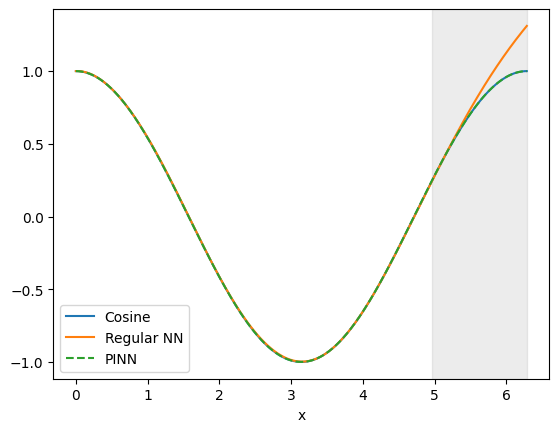

Regular NN | Full grid MSE: 3.446e-03 | Outside training interval: 1.623e-02
PINN       | Full grid MSE: 3.111e-07 | Outside training interval: 2.098e-07


In [8]:
with torch.no_grad():
    pinn_y = pinn(grid)

plt.axvspan(x_train[-1].item(), 2 * math.pi, color='gray', alpha=0.15)
plt.plot(grid, true_y, label='Cosine')
plt.plot(grid, baseline_y, label='Regular NN')
plt.plot(grid, pinn_y, '--', label='PINN')
plt.xlabel('x')
plt.legend()
plt.show()

outside = grid[:, 0] > x_train[-1, 0]
for name, prediction in [('Regular NN', baseline_y), ('PINN', pinn_y)]:
    mse = criterion(prediction, true_y)
    outside_mse = criterion(prediction[outside], true_y[outside])
    print(f'{name:10s} | Full grid MSE: {mse.item():.3e} | Outside training interval: {outside_mse.item():.3e}')

We can also check the derivatives of the PINN on the same grid. For the cosine, the first derivative is $-\sin(x)$ and the second derivative is $-\cos(x)$.

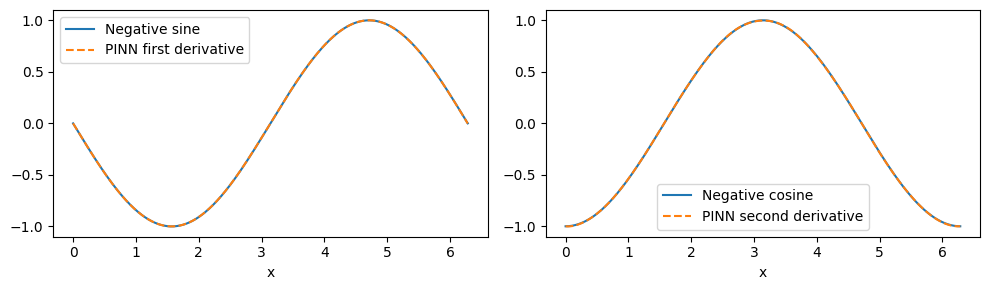

First derivative MSE:  4.297e-07
Second derivative MSE: 2.666e-06


In [9]:
x = grid.detach().requires_grad_()
y = pinn(x)
dy_dx = torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]
d2y_dx2 = torch.autograd.grad(dy_dx, x, torch.ones_like(dy_dx))[0]
dy_dx = dy_dx.detach()

true_dy = -torch.sin(grid)
true_d2y = -true_y

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
axes[0].plot(grid, true_dy, label='Negative sine')
axes[0].plot(grid, dy_dx, '--', label='PINN first derivative')
axes[1].plot(grid, true_d2y, label='Negative cosine')
axes[1].plot(grid, d2y_dx2, '--', label='PINN second derivative')
for ax in axes:
    ax.set_xlabel('x')
    ax.legend()
fig.tight_layout()
plt.show()

print(f'First derivative MSE:  {criterion(dy_dx, true_dy).item():.3e}')
print(f'Second derivative MSE: {criterion(d2y_dx2, true_d2y).item():.3e}')